# 09 - A2b: positive co-motion support on F1

## 1. Audit kontribusi sebelum eksperimen

Audit ini menggunakan komponen run A2a yang tersimpan; legacy control di dalamnya identik dengan F1. Source menghitung dekomposisi gap bertanda H-A, support regime, dan kondisi support berlawanan dengan geometry/persistence/legacy. Notebook membaca hasil CSV/JSON.

Komponen bertanda dapat saling meniadakan: absolute_sum bukan persentase kontribusi yang dapat dijumlahkan. Co-motion tetap berbagi proximity/geometry; audit ini tidak membuktikan independensi atau ketepatan label.

In [1]:
from pathlib import Path
from copy import deepcopy
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'games.py').is_file())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.artifacts import list_runs,read_json,read_table
from src.control_contribution_audit import run_contribution_audit
from src.pipeline import run_pipeline
pd.set_option('display.max_columns',None)
REFERENCE_IDS={'F1':'20261115_232213_442294_bf05582d','A1':'20261116_010846_102998_57f79ee9','A2a':'20261116_024834_385542_009f278f'}
runs=list_runs(project_dir=ROOT)
reference_dirs={name:next(Path(r['path']) for r in runs if r['run_id']==rid) for name,rid in REFERENCE_IDS.items()}
STORAGE_CONFIG=ROOT/'config/artifacts_a2b.yaml'
RUN_PREFLIGHT = False
PREFLIGHT_RUN_ID = "20261116_031220_746548_60cfa353"
if RUN_PREFLIGHT:
    preflight_dir=Path(run_contribution_audit(reference_dirs['A2a'],project_dir=ROOT,storage_config_path=STORAGE_CONFIG))
else:
    preflight_dir=next(Path(r['path']) for r in list_runs(project_dir=ROOT) if r['run_id']==PREFLIGHT_RUN_ID)
preflight_manifest=read_json(preflight_dir)
assert preflight_manifest['status']=='completed' and preflight_manifest['entrypoint']=='control_contribution_audit'
print('Preflight audit:',preflight_manifest['run_id'])
display(read_table(preflight_dir,'control_contributions/regime_summary.csv'))
display(read_table(preflight_dir,'control_contributions/component_summary.csv'))
display(read_json(preflight_dir,'control_contributions/metadata.json'))

,half,support_regime,frames,mean_legacy_gap,mean_geometry_gap,mean_persistence_gap,mean_tag_gap,opposes_legacy_frames,opposes_geometry_frames,opposes_persistence_frames,agrees_legacy_frames
0,1,A_only,5996,-1.464299,-0.937682,-0.484664,-0.041953,86,87,88,5910
1,1,H_only,9012,1.551447,0.959796,0.481049,0.110603,159,161,160,8853
2,1,both,1498,0.321030,0.107121,0.146920,0.066989,35,37,37,142
3,1,neither,62961,0.108331,0.047977,0.028992,0.031362,0,0,0,0
4,2,A_only,5551,-1.378997,-0.871831,-0.469092,-0.038074,168,162,152,5383
5,2,H_only,7740,1.468413,0.900185,0.480476,0.087752,133,140,141,7607
6,2,both,1754,0.288713,0.087671,0.145797,0.055245,46,47,45,142
7,2,neither,61411,0.059781,0.019488,0.011023,0.029269,0,0,0,0


,component,signed_sum,absolute_sum,median_abs,p95_abs
0,distance_gap,5772.100079,30123.186462,0.037568,0.753679
1,signed_margin_gap,3914.868971,26213.374890,0.083401,0.492146
2,persistence_gap,5522.233730,41340.391883,0.409091,0.500000
3,tag_gap,5182.350000,19859.550000,0.150000,0.300000
4,legacy_gap,20391.552780,108174.280317,0.531791,1.822013
5,support_difference,5103.200000,27830.400000,0.000000,1.000000


{'semantics': 'signed H-A components; absolute sums are not additive shares because signed components may cancel', 'support': 'existing causal qualified co-motion gates; not labels, calibrated confidence or independent evidence', 'limitation': 'shared proximity threshold and nearest-point geometry; opposing preferences do not prove either is correct or information is independent', 'scope': 'natural frames exclude forced D if supplied; no GT, model ranking or threshold selection'}

Preflight audit: 20261116_031220_746548_60cfa353


## 2. Interpretasi preflight dan batas independensi

Pada kedua babak, support satu tim biasanya searah dengan geometry dan persistence. Ada beberapa frame dengan support berlawanan, tetapi disagreement tidak membuktikan support benar. Co-motion berbagi syarat proximity dan nearest-point tracking; menambah bonus dapat memperkuat informasi yang sudah dihitung. Audit ini bersifat deskriptif, bukan validasi acquisition.

Eksperimen tetap memakai **satu bobot awal 0.5**, sama dengan bobot maksimum persistence lama per tim. Ini hipotesis skala yang dicatat sebelum melihat hasil kandidat, bukan hasil pencarian parameter. Maksimum perubahan gap H-A dari bonus adalah +/-0.5; bobot itu tidak dipilih dari jumlah possession atau public GT.

## 3. Model A2b: dukungan positif pada F1

`control.acquisition.application: bonus` mempertahankan legacy score lalu menambahkan `bonus_weight * acquisition_gate_i` pada tim i. Qualified gate mensyaratkan cue saat ini, kualitas dan sejarah yang sama dengan A1. Jika support nol, skor tim itu persis legacy; tidak ada kontraksi gap, fallback unavailable, state incumbent, atau hold possession. Jika bonus H=A, tambahan relatif saling meniadakan setelah F1 max-centering. Decoder, transition hint, Live/Dead, boundary dan D1 tetap seperti F1.

Skor adalah utility, bukan probabilitas atau bukti controlled possession. Bonus dapat mengubah urutan H/A bila support berlawanan dengan geometri; ini harus diuji, bukan dianggap benar.

In [2]:
MODEL_CONFIG=ROOT/'config/a2b.yaml'
config=yaml.safe_load(MODEL_CONFIG.read_text(encoding='utf-8-sig'))
f1_manifest=read_json(reference_dirs['F1']);f1_pass=f1_manifest['final_core_pass']
a1_manifest=read_json(reference_dirs['A1']);a1_pass=a1_manifest['final_core_pass']
check=deepcopy(config);acq=check['control'].pop('acquisition')
assert check==read_json(reference_dirs['F1'],'config/model.json')
thresholds=deepcopy(acq);assert thresholds.pop('application')=='bonus'
assert thresholds.pop('bonus_weight')==config['control']['persistence_weight']==0.5
assert thresholds==read_json(reference_dirs['A1'],'config/model.json')['control']['acquisition']
assert not acq.get('fallback_unavailable',False)
print('F1 parent:',REFERENCE_IDS['F1'],'preflight:',preflight_manifest['run_id'])
display(acq)

{'enabled': True, 'window_frames': 5, 'minimum_support_fraction': 0.6, 'maximum_distance_m': 2.5, 'maximum_relative_speed_mps': 3.0, 'minimum_player_quality': 0.65, 'application': 'bonus', 'bonus_weight': 0.5}

F1 parent: 20261115_232213_442294_bf05582d preflight: 20261116_031220_746548_60cfa353


## 4. Pipeline run terpisah

RUN_A2B=True membuat run penuh baru dengan config a2b.yaml dan storage artifacts_a2b.yaml. Setelah contoh selesai, default False membuka run ID yang dipatok. Preflight adalah diagnostic-only run, bukan submission run. Folder kandidat menyimpan snapshot config, semua intermediate, diagnostics dan validator format.

In [3]:
RUN_A2B = False
A2B_RUN_ID = "20261116_032142_912812_df9f9049"
if RUN_A2B:
    result=run_pipeline(config,project_dir=ROOT,storage_config_path=STORAGE_CONFIG,
        execution_metadata={'experiment':'A2b_positive_comotion','parent_run_id':REFERENCE_IDS['F1'],
            'reference_a1_run_id':REFERENCE_IDS['A1'],'reference_a2a_run_id':REFERENCE_IDS['A2a'],
            'preflight_run_id':preflight_manifest['run_id'],'notebook':'notebooks/09_positive_comotion_experiment.ipynb',
            'model_config_source':str(MODEL_CONFIG)})
    run_dir=Path(result.artifact_dir)
else:
    candidates=[r for r in list_runs(project_dir=ROOT)
        if read_json(r['path']).get('execution',{}).get('experiment')=='A2b_positive_comotion']
    if not candidates:raise RuntimeError('Belum ada run A2b; gunakan RUN_A2B=True')
    run_dir=next(Path(r['path']) for r in candidates if r['run_id']==A2B_RUN_ID) if A2B_RUN_ID else Path(candidates[-1]['path'])
manifest=read_json(run_dir);core_pass=manifest['final_core_pass']
assert manifest['status']=='completed' and read_json(run_dir,'config/model.json')==config
print('A2b run:',manifest['run_id'],'folder:',run_dir)
display(read_json(run_dir,'submission/validator/result.json'))

{'status': 'passed', 'message': 'OK    baseline_a2b.csv\n      199319 rows, frame 0..199318\n\n      label counts\n        H    96179   48.3%\n        A    59681   29.9%\n        D     2997    1.5%\n        X    40462   20.3%\n\n      reports 1066 possessions of mean 5.8 s\n      (counted with each X as a gap; the scorer bridges abstentions inside a real\n       possession, so its count can be lower than this one)\n\nValid. Note this checks the format only -- it says nothing about whether the labels are right.\nScore it against the public ground truth with run_evaluation.py.'}

A2b run: 20261116_032142_912812_df9f9049 folder: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg\artifacts\20261116_032142_912812_df9f9049


## 5. Isolasi dan schema artefak

`control/components.csv` menyediakan bonus_h, bonus_a, bonus_gap, legacy/adjusted scores, qualified support, status, a1_h_score/a1_a_score (counterfactual A1), fallback_applied dan effective_gate. Dalam bonus mode, effective_gate=1 adalah koefisien legacy yang dipertahankan, bukan support penuh. Raw winner_gate masih menjelaskan support A1 dan tidak lagi mengalikan skor.

`diagnostics/control_contributions/` mengulang audit preflight pada fitur run baru; harus identik. `diagnostics/final/acquisition/` menyimpan ringkasan bonus. Zero raw support tidak boleh dibaca sebagai gap yang dihapus pada A2b. Utility tim terbaik setelah F1 tetap raw Live, sehingga bonus kontrol tidak menambah keunggulan Live terhadap D.

Field zero_gate_* dan episode zero gate diwarisi dari kualifikasi raw A1; ini bukan evidence yang dihapus A2b. Khusus zero_gate_removed_nonzero_gap_frames, namanya menyatakan kontraksi hipotetis A1. Pada bonus mode, effective_gate=1 mempertahankan koefisien legacy. removed_gap_sum dapat positif jika bonus tim lawan memperkecil besar gap total, meskipun tidak ada komponen legacy yang dihapus.


In [4]:
def join_frame(left,right):
    assert left.frame.is_unique and right.frame.is_unique
    assert np.array_equal(np.sort(left.frame),np.sort(right.frame))
    assert not (set(left.columns)&(set(right.columns)-{'frame'}))
    return left.merge(right,on='frame',validate='one_to_one',sort=True)

paths=[('features/initial/frames.csv','features/initial/frames.csv'),('features/initial/events.csv','features/initial/events.csv')]
for stage,name in [('quality','frames.csv'),('events','frames.csv'),('live_dead','frames.csv'),('fusion','transition_hint.csv'),('fusion','stop_hint.csv'),('fusion','restart_hint.csv')]:
    paths.append((f'core/{f1_pass}/{stage}/{name}',f'core/{core_pass}/{stage}/{name}'))
checks=[]
for old,new in paths:
    same=f1_manifest['files'][old]['sha256']==manifest['files'][new]['sha256'];assert same,new
    checks.append({'artifact':new,'same_sha256':same})
display(pd.DataFrame(checks))
c=read_table(run_dir,f'core/{core_pass}/control/components.csv')
f1_control=read_table(reference_dirs['F1'],f'core/{f1_pass}/control/scores.csv')
a1_control=read_table(reference_dirs['A1'],f'core/{a1_pass}/control/scores.csv')
np.testing.assert_array_equal(c.frame,f1_control.frame);np.testing.assert_array_equal(c.frame,a1_control.frame)
np.testing.assert_array_equal(c[['legacy_h_score','legacy_a_score']],f1_control[['H','A']])
np.testing.assert_array_equal(c[['a1_h_score','a1_a_score']],a1_control[['H','A']])
a1_c=read_table(reference_dirs['A1'],f'core/{a1_pass}/control/components.csv')
np.testing.assert_array_equal(c.frame,a1_c.frame)
raw=[k for k in a1_c if k.startswith(('pair_valid_','relative_speed_','acquisition_','primary_reason_','evidence_status_','winner_fail_'))]+['winner_gate','winner_primary_reason','winner_evidence_status','legacy_winner','winner_tie']
pd.testing.assert_frame_equal(c[raw],a1_c[raw],check_exact=True)
for name in ['frames.csv','regime_summary.csv','component_summary.csv']:
    pd.testing.assert_frame_equal(read_table(preflight_dir,f'control_contributions/{name}'),read_table(run_dir,f'diagnostics/control_contributions/{name}'),check_exact=True)
features=read_table(run_dir,'features/initial/frames.csv')
t=features[['frame','half','graded','ball_ok','ball_speed2d_mps']].copy()
t=join_frame(t,c[['frame','bonus_h','bonus_a','bonus_gap','acquisition_gate_h','acquisition_gate_a','winner_evidence_status']])
for name,folder in {**reference_dirs,'A2b':run_dir}.items():
    pm=read_json(folder)['final_core_pass'];prefix=name.lower()
    scores=read_table(folder,f'core/{pm}/fusion/state_log_scores.csv').rename(columns={k:f'{prefix}_{k}' for k in ['H','A','D']})
    t=join_frame(t,scores)
    t=join_frame(t,read_table(folder,'result/labels.csv').rename(columns={'label':f'{prefix}_final'}))
t=join_frame(t,read_table(run_dir,f'core/{core_pass}/decode/labels.csv').rename(columns={'label':'a2b_decoded'}))
t=join_frame(t,read_table(run_dir,f'core/{core_pass}/fusion/control_components.csv')[['frame','forced_d']])
np.testing.assert_array_equal(t.frame,c.frame)
natural=t.graded&~t.forced_d
np.testing.assert_array_equal(t.a2b_D,t.f1_D)
np.testing.assert_array_equal(t[['a2b_H','a2b_A']].max(axis=1),t[['f1_H','f1_A']].max(axis=1))
np.testing.assert_allclose((t.a2b_H-t.a2b_A)[~t.forced_d],(t.f1_H-t.f1_A+config['fusion']['team_weight']*t.bonus_gap)[~t.forced_d],rtol=0,atol=1e-12)
print('PASS: upstream, hints, raw support/status, legacy F1, counterfactual A1, contribution audit, best-team and D utility.')

,artifact,same_sha256
0,features/initial/frames.csv,True
1,features/initial/events.csv,True
2,core/initial/quality/frames.csv,True
3,core/initial/events/frames.csv,True
4,core/initial/live_dead/frames.csv,True
5,core/initial/fusion/transition_hint.csv,True
6,core/initial/fusion/stop_hint.csv,True
7,core/initial/fusion/restart_hint.csv,True


PASS: upstream, hints, raw support/status, legacy F1, counterfactual A1, contribution audit, best-team and D utility.


## 6. Verifikasi bonus dan kondisi tanpa support

Bonus harus nonnegative, dibatasi bobot, dan nol tanpa cue yang memenuhi syarat. Ketiadaan support tidak menghapus legacy gap. Equal bonus tidak menambah relative preference. Tidak ada fallback pada A2b. Menguatnya gap lama yang sudah besar adalah efek yang mungkin redundan, bukan bukti tambahan yang independen.

In [5]:
weight=float(acq['bonus_weight'])
np.testing.assert_allclose(c.bonus_h,weight*c.acquisition_gate_h,rtol=0,atol=1e-12)
np.testing.assert_allclose(c.bonus_a,weight*c.acquisition_gate_a,rtol=0,atol=1e-12)
assert c[['bonus_h','bonus_a']].ge(0).all().all() and c[['bonus_h','bonus_a']].le(weight).all().all()
assert not c.fallback_applied.any() and c.fallback_restored_gap.eq(0).all()
assert c.effective_gate.eq(1).all()
for side in ['h','a']:
    inactive=c[f'bonus_{side}'].eq(0)
    np.testing.assert_array_equal(c.loc[inactive,f'adjusted_{side}_score'],c.loc[inactive,f'legacy_{side}_score'])
np.testing.assert_allclose(c.adjusted_h_score,c.legacy_h_score+c.bonus_h,rtol=0,atol=1e-12)
np.testing.assert_allclose(c.adjusted_a_score,c.legacy_a_score+c.bonus_a,rtol=0,atol=1e-12)
print('PASS: bounded positive support; exact legacy preservation with no bonus; no contraction/fallback.')
display(read_json(run_dir,f'core/{core_pass}/control/metadata.json'))
summary=read_json(run_dir,'diagnostics/final/acquisition/summary.json');display(summary)

{'acquisition': {'enabled': True, 'application': 'bonus', 'bonus_weight': 0.5, 'fallback_unavailable': False, 'window_frames': 5, 'minimum_support_fraction': 0.6, 'maximum_distance_m': 2.5, 'maximum_relative_speed_mps': 3.0, 'minimum_player_quality': 0.65}, 'fps': 25.0, 'pitch_m': [105.3, 68.0], 'semantics': 'uncalibrated co-motion support, not possession labels or player identities', 'window': 'trailing fixed denominator; full window inside contiguous half/frame block; current cue required', 'relative_speed': 'norm of change in metric ball-minus-nearest-player vector times FPS; both endpoints reliable and near', 'reason_precedence': ['outside_half', 'missing_ball', 'unreliable_ball_motion', 'low_player_quality', 'invalid_position', 'not_near', 'block_start', 'previous_observation_unavailable', 'previous_not_near', 'relative_speed_high', 'insufficient_history', 'insufficient_support', 'supported'], 'reason_semantics': 'failure flags overlap; primary reason is the first failure in prece

{'natural_frames': 155923, 'zero_gate_frames': 124918, 'zero_gate_already_zero_gap_frames': 31387, 'zero_gate_removed_nonzero_gap_frames': 93531, 'nonzero_legacy_gap_natural_frames': 124536, 'zero_gate_fraction_given_nonzero_gap': 0.7510358450568511, 'removed_gap_sum': 183.751996943434, 'legacy_abs_gap_sum': 108174.2803172204, 'fallback_frames': 0, 'fallback_restored_nonzero_gap_frames': 0, 'fallback_restored_gap_sum': 0.0, 'effective_zero_gate_frames': 0, 'effective_zero_removed_nonzero_gap_frames': 0, 'score_application': 'bonus', 'bonus_active_frames': 31551, 'bonus_differential_frames': 28664, 'bonus_opposes_legacy_frames': 627, 'bonus_abs_gap_sum': 13915.2, 'gap_nonzero_tolerance': 1e-12, 'semantics': 'descriptive proxy failures, not negative possession labels; primary reasons are exclusive by precedence; flags overlap', 'support_distance': 'within same half, natural support only, 0 at supported frame, NaN if no earlier/later support; future distances diagnostic only', 'tie_select

PASS: bounded positive support; exact legacy preservation with no bonus; no contraction/fallback.


## 7. Perbandingan F1, A1, A2a dan A2b

A2b dibandingkan langsung dengan F1. A1/A2a menunjukkan efek kontraksi dan fallback sebelumnya; jumlah possession tidak menjadi target pemilihan model. Tambahan kontrol tidak mengubah local D utility wins pada F1, tetapi jalur D final dapat berubah lewat inferensi temporal.

In [6]:
rows=[]
for name,folder in {**reference_dirs,'A2b':run_dir}.items():
    pm=read_json(folder)['final_core_pass'];diag=read_json(folder,'submission/diagnostics.json')
    core=read_json(folder,f'diagnostics/{pm}/core/dead_score_summary.json')
    seg=read_table(folder,'diagnostics/final/prediction/segment_summary.csv')
    tr=read_table(folder,'diagnostics/final/prediction/transition_counts.csv')
    ha=seg.loc[seg.label.isin(['H','A'])]
    rows.append({'model':name,'HA_spells':diag['possession_spells'],'HA_short_lt_2s':int(ha.segments_lt_2s.sum()),
        'median_HA_duration_s':diag['possession_median_s'],
        'HA_transitions':int(tr.loc[tr['from'].isin(['H','A'])&tr['to'].isin(['H','A']),'count'].sum()),
        'total_transitions':diag['total_transitions'],'natural_D_utility_wins':core['dead_wins_unforced'],
        'natural_D_frames':int(t.loc[natural,f'{name.lower()}_final'].eq('D').sum())})
comparison=pd.DataFrame(rows).set_index('model');display(comparison)
assert comparison.natural_D_utility_wins.nunique()==1
display(pd.crosstab(t.loc[natural,'f1_final'],t.loc[natural,'a2b_final']))
display(pd.crosstab(t.loc[natural,'a2b_decoded'],t.loc[natural,'a2b_final']))

,HA_spells,HA_short_lt_2s,median_HA_duration_s,HA_transitions,total_transitions,natural_D_utility_wins,natural_D_frames
model,,,,,,,
F1,1070,523,2.04,1067,1070,169,63
A1,235,23,12.76,231,236,169,61
A2a,280,25,10.78,276,281,169,61
A2b,1066,517,2.08,1063,1066,169,63


a2b_final,A,D,H
f1_final,,,
A,59592,0,122
D,0,63,0
H,89,0,96057


a2b_final,A,D,H
a2b_decoded,,,
A,59620,0,59
D,0,62,0
H,61,1,96120


## 8. Apakah bonus menambah informasi atau menguatkan geometri yang sama?

Signed gap dari source dipadankan dengan perubahan label yang tersimpan. `opposes_legacy` tidak berarti benar, dan `agrees_legacy` tidak berarti redundant secara statistik. Tabel menunjukkan lokasi efek untuk diuji, bukan label acquisition pertandingan. Perbedaan label di wilayah bonus nol dapat berasal dari jalur temporal global.

In [7]:
contributions=read_table(run_dir,'diagnostics/control_contributions/frames.csv')
u=join_frame(contributions,t[['frame','bonus_h','bonus_a','bonus_gap','f1_final','a2b_final']])
u['changed']=u.f1_final.ne(u.a2b_final)
u['bonus_active']=u.bonus_h.gt(0)|u.bonus_a.gt(0)
u['bonus_preference']=u.bonus_gap.abs().gt(1e-12)
g=u.loc[u.natural]
display(g.groupby(['half','support_regime']).agg(frames=('frame','size'),changed_frames=('changed','sum'),
    bonus_differential_frames=('bonus_preference','sum'),opposes_legacy_frames=('support_opposes_legacy','sum')))
display(g.groupby(['bonus_preference','support_opposes_legacy']).agg(frames=('frame','size'),changed_frames=('changed','sum')))
display(read_table(run_dir,'diagnostics/control_contributions/component_summary.csv'))
print('Bonus dapat menggandakan support yang sudah masuk melalui distance/persistence; tabel ini tidak mengukur accuracy.')

frames  changed_frames  bonus_differential_frames  \
half support_regime                                                      
1    A_only            5996              33                       5996   
     H_only            9012              44                       9012   
     both              1498               9                        177   
     neither          62961              38                          0   
2    A_only            5551              36                       5551   
     H_only            7740              44                       7740   
     both              1754               5                        188   
     neither          61411               2                          0   

                     opposes_legacy_frames  
half support_regime                         
1    A_only                             86  
     H_only                            159  
     both                               35  
     neither                             0  
2    A_only                            168  
     H_only                            133  
     both                               46  
     neither                             0

frames  changed_frames
bonus_preference support_opposes_legacy                        
False            False                   127259              48
True             False                    28037              13
                 True                       627             150

,component,signed_sum,absolute_sum,median_abs,p95_abs
0,distance_gap,5772.100079,30123.186462,0.037568,0.753679
1,signed_margin_gap,3914.868971,26213.374890,0.083401,0.492146
2,persistence_gap,5522.233730,41340.391883,0.409091,0.500000
3,tag_gap,5182.350000,19859.550000,0.150000,0.300000
4,legacy_gap,20391.552780,108174.280317,0.531791,1.822013
5,support_difference,5103.200000,27830.400000,0.000000,1.000000


Bonus dapat menggandakan support yang sudah masuk melalui distance/persistence; tabel ini tidak mengukur accuracy.


## 9. Skenario sintetis dan counterexample

Hasil di diagnostics/acquisition_synthetic/ dihitung dengan scorer produksi, bersama counterfactual F1 dan A1. Kasus meliputi passing, reception/interception sah termasuk singkat, loose/contested ball, occlusion, nearest-point switch, low quality dan stale tag.

Dua kasus bonus tambahan: temporary_challenger_comotion (lawan sesaat lebih dekat sementara co-motion H konsisten) dan misleading_comotion_tag (lawan co-moving, nearest point H berubah, dan tag menyesatkan). Kasus kedua secara sengaja menguji batas: bonus dapat memperkuat tim yang salah meskipun F1 memilih expected team. Expected owner berasal dari konstruksi sintetis, bukan pertandingan.

`passed` pada known_limitation berarti counterexample berhasil ditunjukkan. Lihat jumlah label cocok dan limitation_detected secara terpisah. Mask label mengecualikan +/-6 frame sekitar batas fase/owner; periksa plot untuk timing penuh.

,scenario,passed,expectation_kind,limitation_detected,checked_label_frames,checked_label_matches,f1_checked_label_matches,changed_from_f1_frames,challenge_bonus_differential_frames,a1_checked_label_matches,changed_from_a1_frames,challenge_fallback_fraction,challenge_effective_zero_fraction,challenge_frames,challenge_zero_gate_fraction,challenge_unavailable_fraction,challenge_not_supporting_proxy_fraction,challenge_both_supported_fraction
0,same_team_pass,True,label_and_support,False,142,142,142,0,0,142,0,0.0,0.0,40,1.000000,0.0,1.000000,0.000
1,reception_turnover,True,label_and_support,False,155,155,155,0,87,155,0,0.0,0.0,90,0.033333,0.0,0.033333,0.000
2,short_interception,True,label_and_support,False,142,142,142,0,17,142,0,0.0,0.0,20,0.150000,0.0,0.150000,0.000
3,loose_ball,True,label_and_support,False,115,115,115,0,0,115,0,0.0,0.0,40,1.000000,0.0,1.000000,0.000
4,contested_ball,True,label_and_support,False,115,115,115,0,3,115,0,0.0,0.0,40,0.025000,0.0,0.025000,0.925
5,occlusion,True,label_and_support,False,142,142,142,0,0,142,0,0.0,0.0,40,1.000000,1.0,0.000000,0.000
6,nearest_player_switch,True,label_and_support,False,142,142,142,0,1,142,0,0.0,0.0,40,0.975000,0.0,0.975000,0.000
7,occlusion_same_team_tag,True,label_and_support,False,142,142,142,0,0,142,0,0.0,0.0,40,1.000000,1.0,0.000000,0.000
8,occlusion_turnover_tag,True,label_and_support,False,129,129,129,0,0,129,0,0.0,0.0,40,1.000000,1.0,0.000000,0.000
9,occlusion_turnover_stale_tag,True,known_limitation_stale_tag,True,129,122,122,0,0,122,3,0.0,0.0,40,1.000000,1.0,0.000000,0.000


{'source': 'deterministic synthetic feature sequences only; no competition observations, labels or GT', 'expected_labels': 'scenario construction; loose/contested challenge phases unlabelled; +/-6 frames around phase boundaries excluded from label checks', 'scorer': 'production quality, team_control, live_dead, F1 fusion and temporal decoder; no new scoring logic in notebook', 'meaning': 'passing/switch/occlusion can lose acquisition support despite continued team possession; both-supported contested phase is not assigned a ground-truth owner', 'scope': 'behavioral specification checks, not match accuracy or turnover recall', 'passed_semantics': 'scenario contract; known_limitation_misleading_comotion passes when an opponent co-moving with the ball plus a misleading automatic tag causes errors that F1 avoids;  known_limitation_stale_tag passes when fallback demonstrably retains stale evidence and loses synthetic label matches before reacquisition; inspect checked_label_matches and limi

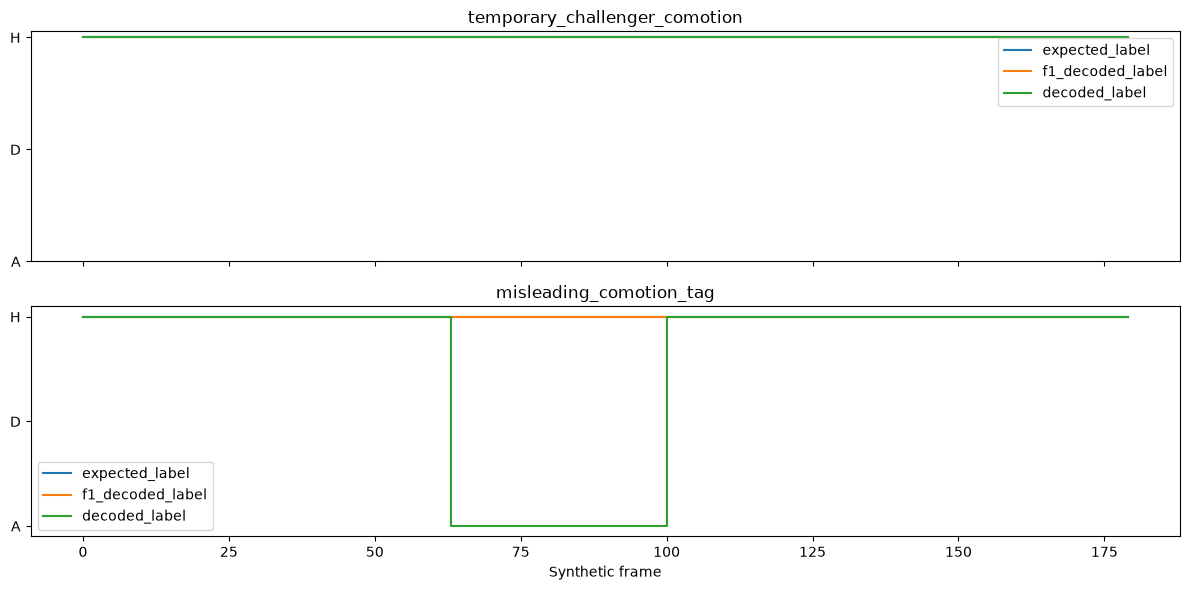

In [8]:
synthetic=read_table(run_dir,'diagnostics/acquisition_synthetic/summary.csv')
synthetic_frames=read_table(run_dir,'diagnostics/acquisition_synthetic/frames.csv')
display(synthetic)
display(read_json(run_dir,'diagnostics/acquisition_synthetic/metadata.json'))
assert len(synthetic)==13 and synthetic.passed.all()
bad=synthetic.loc[synthetic.scenario.eq('misleading_comotion_tag')].iloc[0]
assert bad.limitation_detected and bad.checked_label_matches<bad.f1_checked_label_matches
fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True)
for ax,name in zip(axes,['temporary_challenger_comotion','misleading_comotion_tag']):
    s=synthetic_frames.loc[synthetic_frames.scenario.eq(name)]
    for label in ['expected_label','f1_decoded_label','decoded_label']:
        ax.step(s.frame,s[label].map({'H':1,'A':-1,'D':0}),where='post',label=label)
    ax.set_yticks([-1,0,1],['A','D','H']);ax.set_title(name);ax.legend()
axes[-1].set_xlabel('Synthetic frame');plt.tight_layout();plt.show()

## 10. Contoh pertandingan dipilih algoritma

Pilih frame natural observed dengan perubahan bonus gap terbesar yang berlawanan dengan legacy, jika ada; jika tidak, pilih bonus gap terbesar. Ini contoh intervensi, bukan label ground truth. Panel skor membandingkan signed gap dan panel label memisahkan decoded/final.

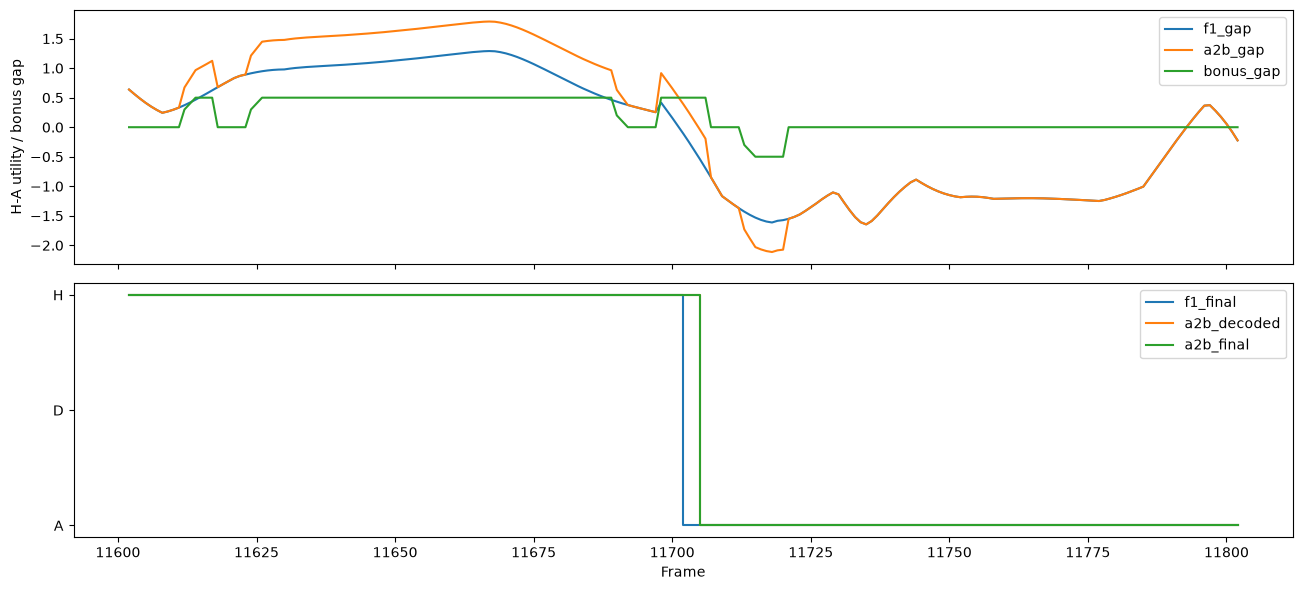

In [9]:
mask=u.natural&u.support_opposes_legacy&t.ball_ok
if not mask.any():mask=u.natural&u.bonus_preference
center=int(u.loc[mask,'bonus_gap'].abs().idxmax())
frame=int(u.loc[center,'frame']);half=int(u.loc[center,'half'])
w=t.loc[t.frame.between(frame-100,frame+100)&t.half.eq(half)&~t.forced_d].copy()
w['f1_gap']=w.f1_H-w.f1_A;w['a2b_gap']=w.a2b_H-w.a2b_A
fig,axes=plt.subplots(2,1,figsize=(13,6),sharex=True)
w.plot(x='frame',y=['f1_gap','a2b_gap','bonus_gap'],ax=axes[0]);axes[0].set_ylabel('H-A utility / bonus gap')
for label in ['f1_final','a2b_decoded','a2b_final']:
    axes[1].step(w.frame,w[label].map({'H':1,'A':-1,'D':0,'X':np.nan}),where='post',label=label)
axes[1].set_yticks([-1,0,1],['A','D','H']);axes[1].legend();axes[1].set_xlabel('Frame')
plt.tight_layout();plt.show()

## 11. Arah keputusan

| Hasil | Interpretasi / keputusan |
|---|---|
| Legacy tetap tersedia saat support nol | Masalah penghapusan evidence A1 diatasi secara mekanisme |
| Mayoritas bonus searah geometry/persistence | Risiko penghitungan ulang; jangan menyebutnya evidence independen |
| Opposing support mengubah preferensi lokal | Uji skenario kontrol dan counterexample; belum menunjukkan preferensi baru benar |
| Turnover pendek sah bertahan | Skenario tersebut responsif; bukan ukuran recall turnover pertandingan |
| Counterexample bonus salah terbukti | Bonus bukan detector acquisition yang tervalidasi; pertahankan batas klaim |
| Short spell turun/naik | Indikator perilaku, bukan dasar tunggal pemilihan model |
| Label berubah di luar bonus | Pengaruh jalur bersama; scorer lokal tidak harus berubah |

Belum menggabungkan D1 atau mengubah decoder/hint. Tidak ada pemilihan parameter dari public GT atau jumlah possession. Kandidat memerlukan validasi independen yang diizinkan.

In [10]:
display(Markdown(f"**Run {manifest['run_id']}:** bonus aktif pada {summary['bonus_active_frames']:,} frame alami; "
    f"bonus H-A berbeda pada {summary['bonus_differential_frames']:,} frame; "
    f"berlawanan dengan legacy pada {summary['bonus_opposes_legacy_frames']:,} frame. "
    f"Short H/A F1 {int(comparison.loc['F1','HA_short_lt_2s'])} -> A2b {int(comparison.loc['A2b','HA_short_lt_2s'])}. "
    "Legacy tidak dihapus ketika support absen; seluruh isolasi lolos. Ini efek mekanisme, bukan accuracy/spellF1."))
print('Misleading co-motion synthetic:',int(bad.checked_label_matches),'/',int(bad.checked_label_frames),
      'vs F1:',int(bad.f1_checked_label_matches),'contract:',bad.expectation_kind)
print('Bobot tetap 0.5; tidak diubah berdasarkan hasil kandidat.')

**Run 20261116_032142_912812_df9f9049:** bonus aktif pada 31,551 frame alami; bonus H-A berbeda pada 28,664 frame; berlawanan dengan legacy pada 627 frame. Short H/A F1 523 -> A2b 517. Legacy tidak dihapus ketika support absen; seluruh isolasi lolos. Ini efek mekanisme, bukan accuracy/spellF1.

Misleading co-motion synthetic: 115 / 142 vs F1: 142 contract: known_limitation_misleading_comotion
Bobot tetap 0.5; tidak diubah berdasarkan hasil kandidat.


## 12. Simpulan run A2b dan keputusan

Preflight **20261116_031220_746548_60cfa353** dilakukan sebelum scorer bonus diimplementasikan. Run kandidat **20261116_032142_912812_df9f9049** memakai F1 sebagai parent. Fitur, quality, event, hint, Live/Dead, legacy scores dan raw support/status identik dengan pembanding. Audit signed contribution pada kandidat juga identik dengan preflight. Bobot tetap **0.5**, tidak diubah setelah melihat hasil.

| Ukuran | F1 | A1 | A2a | A2b |
|---|---:|---:|---:|---:|
| HA spells | 1,070 | 235 | 280 | 1,066 |
| HA spells <2 s | 523 | 23 | 25 | 517 |
| Median HA duration (s) | 2.04 | 12.76 | 10.78 | 2.08 |
| HA transitions | 1,067 | 231 | 276 | 1,063 |
| Natural final D frames | 63 | 61 | 61 | 63 |

**Yang terbukti secara mekanisme:** legacy tetap tersedia ketika support absen; bonus per tim dibatasi 0.5; equal bonus tidak menambah relative preference; tidak ada unavailable fallback atau contraction yang diterapkan. Utility tim terbaik setelah F1 dan utility D tidak berubah. Validator format dan seluruh pemeriksaan isolasi lolos.

**Efek pertandingan kecil:** bonus aktif pada **31,551 frame alami**, memberikan tambahan H-A yang berbeda pada **28,664 frame**, tetapi hanya **627** berlawanan dengan legacy. Pada kelompok 28,037 frame dengan differential bonus tanpa opposition, hanya 13 label akhir berubah. Pada kelompok opposing 627 frame, 150 label berubah. Ada 48 perubahan pada wilayah tanpa differential bonus, konsisten dengan efek jalur bersama. Label berbeda tidak membuktikan preferensi baru benar. Short spells turun enam, bukan bukti peningkatan accuracy/spellF1 atau solusi fragmentasi.

**Hasil sintetis membatasi adopsi:** tiga belas kontrak skenario lolos, termasuk counterexample yang sengaja diharapkan mengungkap kesalahan. Pada temporary_challenger_comotion, F1 dan A2b sama-sama cocok pada **143/143** frame yang diperiksa; belum ada keuntungan label A2b pada kasus tersebut. Passing dan genuine short interception juga dipertahankan, tetapi F1 sudah memenuhi pemeriksaan itu.

Sebaliknya, pada **misleading_comotion_tag**, A2b hanya cocok pada **115/142** frame sintetis yang diperiksa, sedangkan F1 **142/142**. Lawan yang bergerak bersama bola, pergantian nearest point H dan tag yang menyesatkan dapat membuat bonus memperkuat tim yang salah. passed=True di sini berarti kontrak known_limitation berhasil ditunjukkan, bukan prediksi benar. Mask +/-6 frame tidak mengukur seluruh ketepatan boundary; plot menampilkan urutan lengkap. Stale tag juga tetap menjadi batas (122/129 pada kedua model).

**Interpretasi:** menghapus syarat acquisition universal menyelesaikan pelemahan evidence yang luas pada A1 secara desain. Namun proxy co-motion yang sama belum memberikan manfaat label yang terbukti; mayoritas dukungannya searah dengan geometri/persistence, dan counterexample memperlihatkan risiko tambahan. Data pertandingan tidak menyediakan label yang sah untuk menyatakan perbedaan kecil itu perbaikan.

**Keputusan:** A2b disimpan sebagai eksperimen terpisah dan **belum direkomendasikan mengganti F1**. Tidak meningkatkan bobot atau mengubah window hanya untuk mengejar jumlah spell. Tidak menggabungkan D1 atau mengganti decoder pada tahap ini. Validasi independen yang diizinkan, atau representasi acquisition yang dapat membedakan co-moving opponent dari controlled possession, diperlukan sebelum klaim peningkatan. Audit asosiasi temporal pemain dan hubungan acquisition vs continuation perlu mempertahankan batas bahwa nearest point/track slot bukan identitas permanen.
